# **Drive setup**

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/cv-longtail"

Mounted at /content/drive


In [ ]:
import os
for sub in ["data", "splits", "checkpoints", "results"]:
    os.makedirs(f"{ROOT}/{sub}", exist_ok=True)
print(os.listdir(ROOT))

['data', 'splits', 'checkpoints', 'results']


In [ ]:
from torchvision.datasets import CIFAR10

ROOT = "/content/drive/MyDrive/cv-longtail"

train = CIFAR10(root=f"{ROOT}/data", train=True,  download=True)
test  = CIFAR10(root=f"{ROOT}/data", train=False, download=True)

100%|██████████| 170M/170M [24:06<00:00, 118kB/s]


50000 10000
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
print(len(train), len(test))   # expect 50000 10000
print(train.classes)

50000 10000
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
import numpy as np
print(np.bincount(train.targets))   # expect [5000 5000 ... 5000]

[5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


In [ ]:
print(type(train.data), train.data.shape)      # the images
print(type(train.targets), len(train.targets)) # the labels
print(train.classes)                           # the label names

<class 'numpy.ndarray'> (50000, 32, 32, 3)
<class 'list'> 50000
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


[6, 9, 9, 4, 1, 1, 2, 7, 8, 3]
['frog', 'truck', 'truck', 'deer', 'automobile', 'automobile', 'bird', 'horse', 'ship', 'cat']
(32, 32) 6 frog


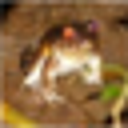

In [ ]:
print(train.targets[:10])                          # labels of first 10 images
print([train.classes[t] for t in train.targets[:10]])  # same, as names

img, label = train[0]                              # indexing gives (image, label)
print(img.size, label, train.classes[label])
img.resize((128, 128))                             # displays the image in Colab

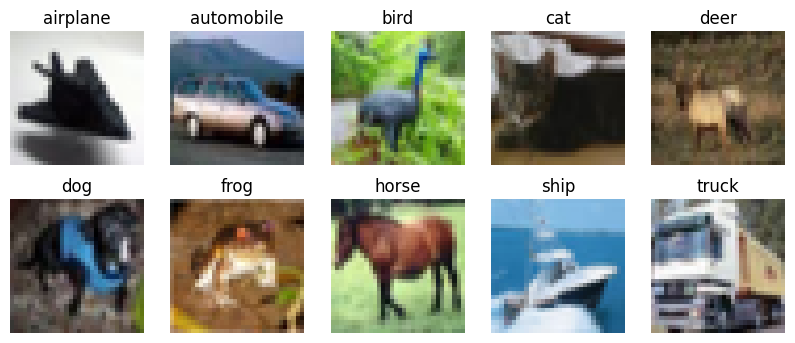

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for c, ax in enumerate(axes.flat):
    i = train.targets.index(c)          # first image of class c
    ax.imshow(train.data[i])
    ax.set_title(train.classes[c])
    ax.axis("off")
plt.show()

# **Builder**

**Splits**

In [ ]:
import numpy as np, json

def make_lt_indices(targets, C=10, rho=100, n_max=5000, seed=0):
    rng = np.random.RandomState(seed)
    targets = np.array(targets)
    counts = [int(n_max * rho ** (-i / (C - 1))) for i in range(C)]
    idx = []
    for c, n in enumerate(counts):
        cls_idx = np.where(targets == c)[0]
        idx += rng.choice(cls_idx, n, replace=False).tolist()
    return sorted(idx), counts

idx, counts = make_lt_indices(train.targets, rho=100)
print(counts, len(idx))
assert len(idx) == 12406

with open(f"{ROOT}/splits/c10lt_rho100_seed0.json", "w") as f:
    json.dump({"indices": idx, "counts": counts}, f)

[5000, 2997, 1796, 1077, 645, 387, 232, 139, 83, 50] 12406


**Group definitions**

In [ ]:
groups_c10 = {"many": [0, 1, 2], "medium": [3, 4, 5, 6], "few": [7, 8, 9]}

**Metrics**

In [ ]:
import numpy as np

def compute_metrics(preds, targets, groups):
    preds, targets = np.array(preds), np.array(targets)
    C = int(targets.max()) + 1
    per_class = [(preds[targets == c] == c).mean() for c in range(C)]
    out = {"overall": float((preds == targets).mean()),
           "per_class": [float(a) for a in per_class]}
    for name, cls in groups.items():
        out[name] = float(np.mean([per_class[c] for c in cls]))
    return out